In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the uploaded files
X = pd.read_csv('X_features.csv')
y = pd.read_csv('y_target.csv').squeeze()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\nFirst 5 rows of X:")
display(X.head())

print("\nFirst 5 values of y:")
display(y.head())

X shape: (1424, 17)
y shape: (1424,)

X columns:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'number_of_monitoring_stations', 'Year', 'Is_Lohri_Month', 'Is_Diwali_Season', 'Is_Paddy_Harvesting']

First 5 rows of X:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,number_of_monitoring_stations,Year,Is_Lohri_Month,Is_Diwali_Season,Is_Paddy_Harvesting
0,63.220000,135.760000,46.810000,15.960000,45.210000,24.730000,1.110000,7.79,8.10,9.1400,0.3800,0.780000,3.0,2020,1,0,0
1,57.483333,118.843333,32.276667,15.643333,31.983333,42.996667,1.013333,7.85,9.48,8.4400,0.3800,0.803333,2.0,2023,1,0,0
2,51.746667,101.926667,17.743333,15.326667,18.756667,61.263333,0.916667,7.91,10.86,7.7400,0.3800,0.826667,3.0,2024,1,0,0
3,46.010000,85.010000,3.210000,15.010000,5.530000,79.530000,0.820000,7.97,12.24,7.0400,0.3800,0.850000,3.0,2020,0,0,0
4,38.725000,77.147500,9.092500,16.092500,12.092500,72.545000,0.790000,8.32,11.74,6.6375,0.3175,0.965000,3.0,2023,0,0,0



First 5 values of y:


,AQI
0,132
1,306
2,239
3,95
4,110


In [5]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Missing values in X:
PM2.5                            0
PM10                             0
NO                               0
NO2                              0
NOx                              0
NH3                              0
CO                               0
SO2                              0
O3                               0
Benzene                          0
Toluene                          0
Xylene                           0
number_of_monitoring_stations    0
Year                             0
Is_Lohri_Month                   0
Is_Diwali_Season                 0
Is_Paddy_Harvesting              0
dtype: int64

Missing values in y:
0


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1139
Testing samples: 285


In [7]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [8]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Linear Regression
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

# Random Forest
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

In [10]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        linear_mae,
        rf_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse
    ],
    'R²': [
        linear_r2,
        rf_r2
    ]
})

display(results.round(3))

,Model,MAE,RMSE,R²
0,Linear Regression,42.202,53.740,0.455
1,Random Forest,30.605,41.675,0.672


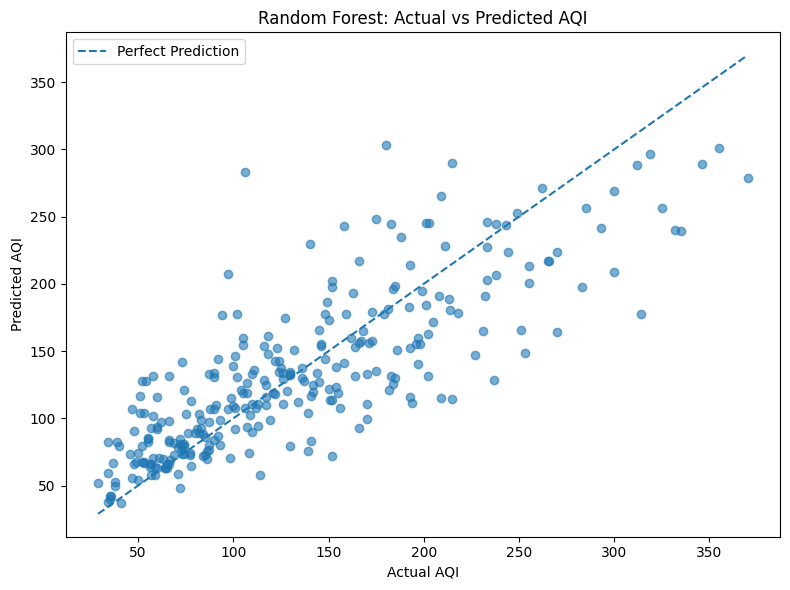

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.6
)

# Perfect prediction line
minimum = min(y_test.min(), rf_pred.min())
maximum = max(y_test.max(), rf_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Random Forest: Actual vs Predicted AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
rf_residuals = y_test - rf_pred

print("Mean residual:", round(rf_residuals.mean(), 3))
print("Minimum residual:", round(rf_residuals.min(), 3))
print("Maximum residual:", round(rf_residuals.max(), 3))

Mean residual: 0.447
Minimum residual: -177.475
Maximum residual: 136.49


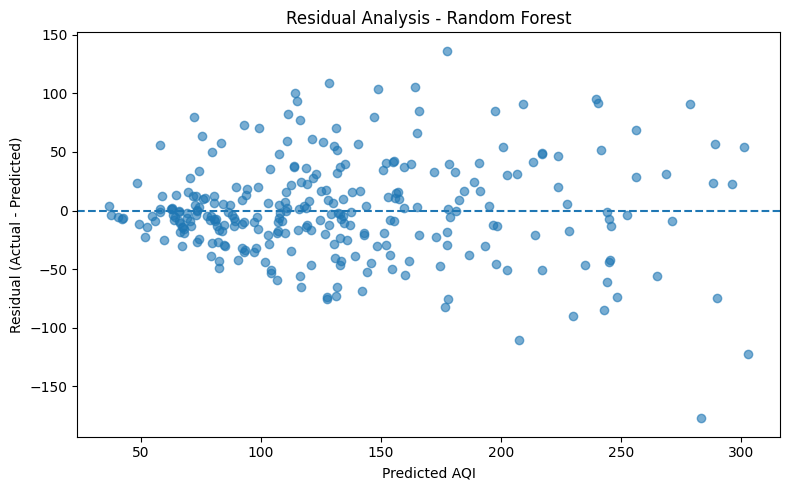

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rf_pred,
    rf_residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle='--'
)

plt.xlabel("Predicted AQI")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Random Forest")

plt.tight_layout()
plt.show()

In [14]:
error_df = pd.DataFrame({
    'Actual AQI': y_test.values,
    'Predicted AQI': rf_pred,
    'Residual': rf_residuals.values,
    'Absolute Error': np.abs(rf_residuals.values)
})

error_df = error_df.sort_values(
    'Absolute Error',
    ascending=False
)

display(error_df.head(10))

,Actual AQI,Predicted AQI,Residual,Absolute Error
81,106,283.475,-177.475,177.475
119,314,177.510,136.490,136.490
168,180,302.895,-122.895,122.895
36,97,207.445,-110.445,110.445
279,237,128.250,108.750,108.750
175,270,164.180,105.820,105.820
170,253,148.915,104.085,104.085
187,215,114.200,100.800,100.800
94,335,239.565,95.435,95.435
257,209,115.060,93.940,93.940


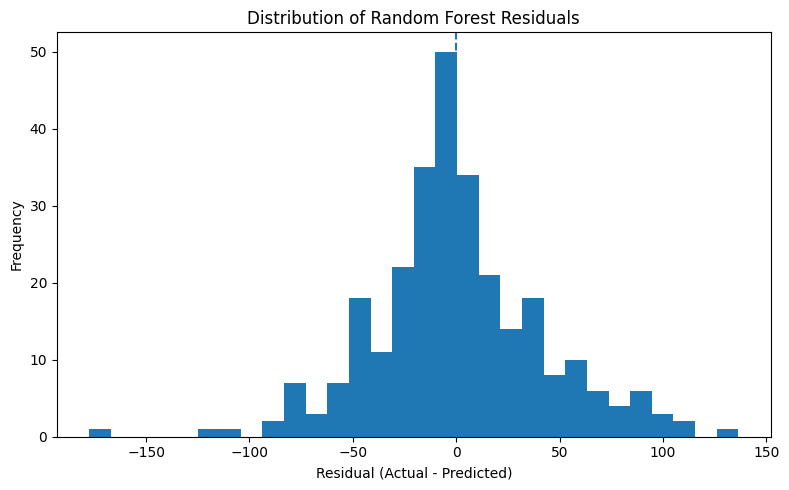

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    rf_residuals,
    bins=30
)

plt.axvline(
    0,
    linestyle='--'
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Random Forest Residuals")

plt.tight_layout()
plt.show()